<a href="https://colab.research.google.com/github/FrancisQL/Computer_Vision/blob/main/Notebooks/AL09-ObjDetection/AL9_Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AL9 — Object Detection: Finding Farm Buildings with YOLO
**MCS 3950 Computer Vision · UPEI · Fall 2026 · Friday Nov 20**

In **L15** you met detectors: boxes, IoU, precision and recall, and a YOLO fine-tuned on 12 cabins.
Today you build the whole thing yourself, on the kind of photo a project uses: **1968 provincial
air photos at 0.5 m per pixel**, looking straight down on PEI farmsteads (houses, barns, sheds).

| Part | Topic | Time |
|------|-------|------|
| 0 | Setup: the tiles, the boxes, and a COCO detector from above | ~7 min |
| 1 | Labels in YOLO's format | ~7 min |
| 2 | Fine-tune YOLO on 14 tiles | ~10 min |
| 3 | Scoring a detector: IoU matching, precision, recall | ~12 min |
| 4 | The precision–recall curve, AP, and choosing a threshold | ~10 min |
| 5 | Crapaud, once | ~5 min |
| ★ | Bonus: the same model on 1935 | if time |

There are **three tasks** and a few **checkpoint questions**. Before each experiment there is a
🔮 **Predict first** prompt: write your guess down *before* you run the cell.

> **Use a GPU.** In Colab: **Runtime → Change runtime type → T4 GPU**. With a GPU the training in
> Part 2 takes about 2 minutes; on a CPU about 10 minutes (pair up, or start it and do Task 2 by hand
> on paper while it runs).
>
> **Not submitted or graded.** It practises L15 (Test 3 material) and is the starting recipe for any
> project that has to find buildings.

In [1]:
import os, io, json, time, zipfile, urllib.request
os.environ["YOLO_VERBOSE"] = "False"          # keep ultralytics quiet (set before importing it)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
try:
    import ultralytics
except ImportError:                            # Colab: install once (about 30 s)
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    import ultralytics
import torch
from ultralytics import YOLO

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, GREY = "#C8962C", "#B82828", "#1A7A8A", "#2E7D50", "#1A3A5C", "#9AA5B1"
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"ultralytics {ultralytics.__version__} | PyTorch {torch.__version__} on "
      + (torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU"))
if DEVICE == "cpu":
    print("No GPU. Colab: Runtime -> Change runtime type -> T4 GPU, then re-run this cell.\n"
          "On a CPU, Part 2's training takes about 10 minutes.")

ultralytics 8.4.216 | PyTorch 2.14.1+cu130 on Tesla T4


## Part 0 — The tiles and the boxes  `⏱ ~7 min`

`AL9.zip` (~5 MB) holds 19 tiles of **640 × 640 pixels** (320 m × 320 m) cut from the 1968 provincial
orthomosaic at its native 0.5 m per pixel, and a hand-drawn box around every building on them
(`buildings.json`, corners `(x1, y1, x2, y2)` in pixels). None of the tiles is from a project image set.

| Split | Tiles | Where | Buildings | Used for |
|---|---|---|---|---|
| `train` | 14 | Hunter River + Kinkora areas | 119 | learning the weights |
| `val` | 2 | the same two areas | 15 | checking, choosing the threshold |
| `test` | 3 | **Crapaud** (another flight day) | 33 | **once**, at the very end (Part 5) |

**Labelling rule** (one person, by eye): every roofed building whose longer side is at least about
6 m (12 px): houses, barns, sheds, garages. Vehicles, hay piles and anything unclear were left out.
A building joined to another one got its own box when the roofs were clearly separate.

In [2]:
BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")
if not os.path.exists("AL9/buildings.json"):
    with urllib.request.urlopen(BASE + "AL9.zip", timeout=180) as r:
        blob = r.read()
    zipfile.ZipFile(io.BytesIO(blob)).extractall(".")
    print(f"AL9.zip: {len(blob)/1e6:.1f} MB downloaded and extracted")
else:
    print("AL9/: already present")

INFO = json.load(open("AL9/buildings.json"))
SPLITS = INFO["splits"]                                   # {"train": [...], "val": [...], "test": [...]}
TRUTH = {t: np.array(b, float) for t, b in INFO["boxes"].items()}
IMG = {t: cv2.imread(f"AL9/tiles/{t}.png", cv2.IMREAD_GRAYSCALE) for t in TRUTH}
for s, ids in SPLITS.items():
    print(f"{s:5s} {len(ids)} tiles {ids}: {sum(len(TRUTH[t]) for t in ids)} buildings")

AL9.zip: 5.3 MB downloaded and extracted
train 14 tiles ['H1', 'H2', 'H3', 'H4', 'K1', 'K2', 'K3', 'K6', 'H6', 'H8', 'H9', 'K7', 'K8', 'K9']: 119 buildings
val   2 tiles ['H5', 'K4']: 15 buildings
test  3 tiles ['C2', 'C3', 'C4']: 33 buildings


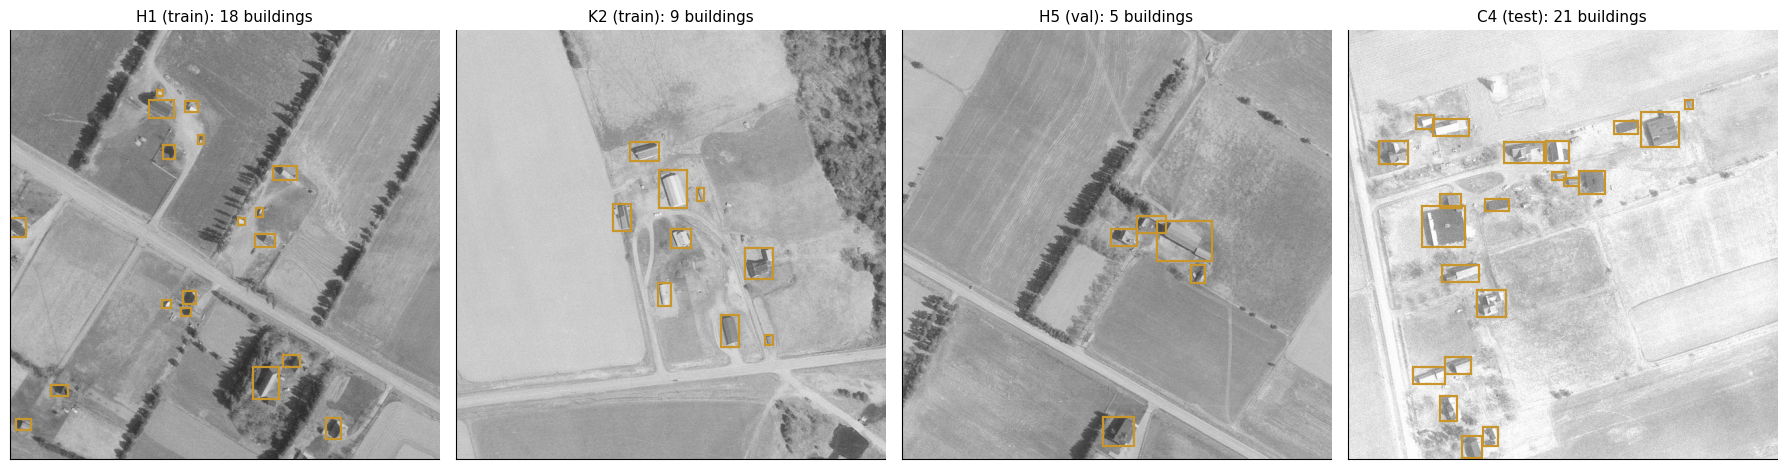

box sizes (longer side): median 32 px = 16 m, smallest 10 px, largest 82 px


In [3]:
def draw(ax, boxes, col, lw=1.6, scores=None):
    for k, b in enumerate(boxes):
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=col, lw=lw))
        if scores is not None:
            ax.text(b[0], b[1] - 3, f"{scores[k]:.2f}", color=col, fontsize=8)

def show(ax, t, title=None):
    ax.imshow(IMG[t], cmap="gray", vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title or t, fontsize=11)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, t in zip(axes, ["H1", "K2", "H5", "C4"]):
    show(ax, t, f"{t} ({[s for s, ids in SPLITS.items() if t in ids][0]}): {len(TRUTH[t])} buildings")
    draw(ax, TRUTH[t], GOLD)
plt.tight_layout(); plt.show()
w = TRUTH["H1"][:, 2] - TRUTH["H1"][:, 0]; h = TRUTH["H1"][:, 3] - TRUTH["H1"][:, 1]
all_b = np.concatenate(list(TRUTH.values()))
side = np.maximum(all_b[:, 2] - all_b[:, 0], all_b[:, 3] - all_b[:, 1])
print(f"box sizes (longer side): median {np.median(side):.0f} px = {np.median(side)/2:.0f} m, "
      f"smallest {side.min():.0f} px, largest {side.max():.0f} px")

### 🔮 A COCO detector, from straight above

L15's YOLO11n was trained on **COCO**: 80 classes of everyday things (people, cars, dogs, cups,
airplanes...), almost all photographed from the side. On L15's oblique cabins it drew boxes in the
right places but called the cabins "train".

**Predict first:** what will the same COCO YOLO find on tile H1, looking straight down on two
farmsteads? Write it down, then run the cell.

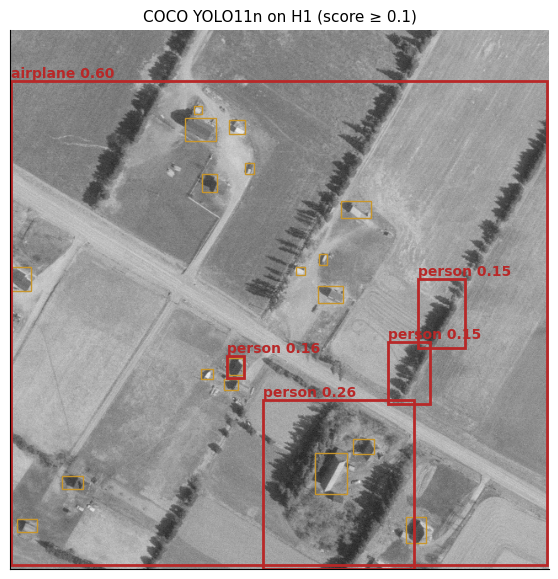

['airplane 0.60', 'person 0.26', 'person 0.16', 'person 0.15', 'person 0.15']


In [4]:
coco = YOLO("yolo11n.pt")                      # COCO-trained; downloads 5.6 MB the first time

def detect(model, t, conf=0.01, img=None):
    '''All boxes the model gives for tile t, best first: list of (x1, y1, x2, y2, score).'''
    img = IMG[t] if img is None else img
    r = model.predict(cv2.cvtColor(img, cv2.COLOR_GRAY2BGR), imgsz=640, conf=conf,
                      device=DEVICE, verbose=False)[0]
    d = [(*b, s) for b, s in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist())]
    names = [r.names[int(c)] for c in r.boxes.cls.tolist()]
    order = np.argsort([-x[4] for x in d])
    return [d[i] for i in order], [names[i] for i in order]

d, names = detect(coco, "H1", conf=0.1)
fig, ax = plt.subplots(figsize=(7, 7))
show(ax, "H1", "COCO YOLO11n on H1 (score ≥ 0.1)")
draw(ax, TRUTH["H1"], GOLD, 1.0)
for (x1, y1, x2, y2, s), n in zip(d, names):
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=RED, lw=2))
    ax.text(x1, y1 - 4, f"{n} {s:.2f}", color=RED, fontsize=10, weight="bold")
plt.show()
print([f"{n} {s:.2f}" for (*_, s), n in zip(d, names)])

**Q0.** What did COCO's YOLO find? Why does knowing 80 everyday classes not help here,
when it did at least find the *places* of L15's cabins?

*Your answer:*

---
## Part 1 — Labels in YOLO's format  `⏱ ~7 min`

`ultralytics` trains from a folder of images and, for each image, a text file with **one line per box**:

```
class  cx  cy  w  h          e.g.   0 0.658 0.492 0.128 0.094
```

where `(cx, cy)` is the box **centre** and `w, h` its width and height, **all divided by the image
size** (so every number is between 0 and 1). Class 0 is our only class, `building`. This is L15
slide 5's corners → centre conversion, plus one division.

**By hand first:** the long barn on tile H5 has corners **(380, 285, 462, 345)** in a 640 × 640 tile.
What is its label line?

**Task 1:** complete `to_yolo`.

In [18]:
def to_yolo(box, W=640, H=640):
    '''box = (x1, y1, x2, y2) in pixels  ->  (cx, cy, w, h) as fractions of the image size'''
    x1, y1, x2, y2 = box
    cx = (x2 + x1)/2 /W
    cy = (y2 + y1)/2 /H
    w = (x2 - x1)/W
    h = (y2 - y1)/H
    return (cx, cy, w, h)
    # ── YOUR CODE HERE ──────────────────────────────────────────────────────────
    # centre = the average of the two corners; width = x2 - x1; then divide x's by W and y's by H
    # ────────────────────────────────────────────────────────────────────────────
    raise NotImplementedError("Task 1: four numbers.")

In [19]:
# Check Task 1
try:
    got = np.round(to_yolo((380, 285, 462, 345)), 3)
    print("H5 barn ->", got)
    assert np.allclose(got, [0.658, 0.492, 0.128, 0.094], atol=0.002), "centre / size / divide?"
    assert np.allclose(to_yolo((0, 0, 640, 640)), [0.5, 0.5, 1, 1]), "a box filling the tile is (0.5, 0.5, 1, 1)"
    assert np.allclose(to_yolo((0, 0, 100, 50), W=1000, H=500), [0.05, 0.05, 0.1, 0.1]), "divide x by W, y by H"
    print("Task 1 OK")
except NotImplementedError:
    print("Complete Task 1 first.")

H5 barn -> [      0.658       0.492       0.128       0.094]
Task 1 OK


**Q1.** Write the H5 barn's label line. Why does YOLO store fractions instead of pixels?

*Your answer:*

### Writing the dataset (given)

One folder per split, one `.png` and one `.txt` per tile, and a small `data.yaml` that tells
`ultralytics` where they are and what class 0 is called.

In [20]:
ROOT = os.path.abspath("al9_data")

def write_dataset():
    for s, ids in SPLITS.items():
        os.makedirs(f"{ROOT}/images/{s}", exist_ok=True); os.makedirs(f"{ROOT}/labels/{s}", exist_ok=True)
        for t in ids:
            cv2.imwrite(f"{ROOT}/images/{s}/{t}.png", IMG[t])
            with open(f"{ROOT}/labels/{s}/{t}.txt", "w") as f:
                for b in TRUTH[t]:
                    f.write("0 " + " ".join(f"{v:.6f}" for v in to_yolo(b)) + "\n")
    with open(f"{ROOT}/data.yaml", "w") as f:
        f.write(f"path: {ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                "names:\n  0: building\n")

try:
    write_dataset()
    print(open(f"{ROOT}/data.yaml").read())
    print("labels/val/H5.txt:\n" + open(f"{ROOT}/labels/val/H5.txt").read())
except NotImplementedError:
    print("Complete Task 1 first.")

path: /content/al9_data
train: images/train
val: images/val
test: images/test
names:
  0: building

labels/val/H5.txt:
0 0.657813 0.492188 0.128125 0.093750
0 0.581250 0.453125 0.068750 0.037500
0 0.517188 0.483594 0.059375 0.039062
0 0.689063 0.567969 0.034375 0.042188
0 0.504687 0.935156 0.071875 0.067187



---
## Part 2 — Fine-tune YOLO on 14 tiles  `⏱ ~10 min`

The L14 recipe, for a detector: start from the COCO weights (the network already knows edges, corners
and blobs), replace the last layer's 80 classes with our 1, and train **every** weight gently.

The settings below are the ones worth knowing (the rest are `ultralytics` defaults):

| Setting | Value | Why |
|---|---|---|
| `epochs` | 100 | 14 photos is tiny: each epoch is only 4 steps of 4 images |
| `imgsz` | 640 | our tiles' own size: no resizing, a small shed stays 12+ px |
| `fliplr`, `flipud` | 0.5, 0.5 | from straight above there is no "up": both flips keep a building a building (AL8) |
| `hsv_v` | 0.6 | random brightness ±60%: flights on different days are lit differently |
| `mosaic` | 0 | the default glues 4 images into one; with this few photos it taught the network to draw huge boxes along tile edges |

🔮 **Predict first:** the validation tiles have **15** buildings. How many will the fine-tuned model
find (score ≥ 0.25), and how many wrong boxes will it draw?

In [21]:
EPOCHS = int(os.environ.get("AL9_EPOCHS", 100))     # ~2 min on a T4 GPU, ~10 min on a 2-core CPU
t0 = time.time()
model = YOLO("yolo11n.pt")
try:
    model.train(data=f"{ROOT}/data.yaml", epochs=EPOCHS, imgsz=640, batch=4, workers=0,
                fliplr=0.5, flipud=0.5, hsv_v=0.6, mosaic=0,
                seed=0, deterministic=True, device=DEVICE, val=False, plots=False, verbose=False,
                project=os.path.abspath("runs_al9"), name="buildings", exist_ok=True)
    model = YOLO(os.path.abspath("runs_al9/buildings/weights/last.pt"))
    print(f"fine-tuned {EPOCHS} epochs in {time.time() - t0:.0f} s")
except Exception as e:
    print("Training failed:", type(e).__name__, e, "\n(Did Part 1 run?)")

fine-tuned 100 epochs in 110 s


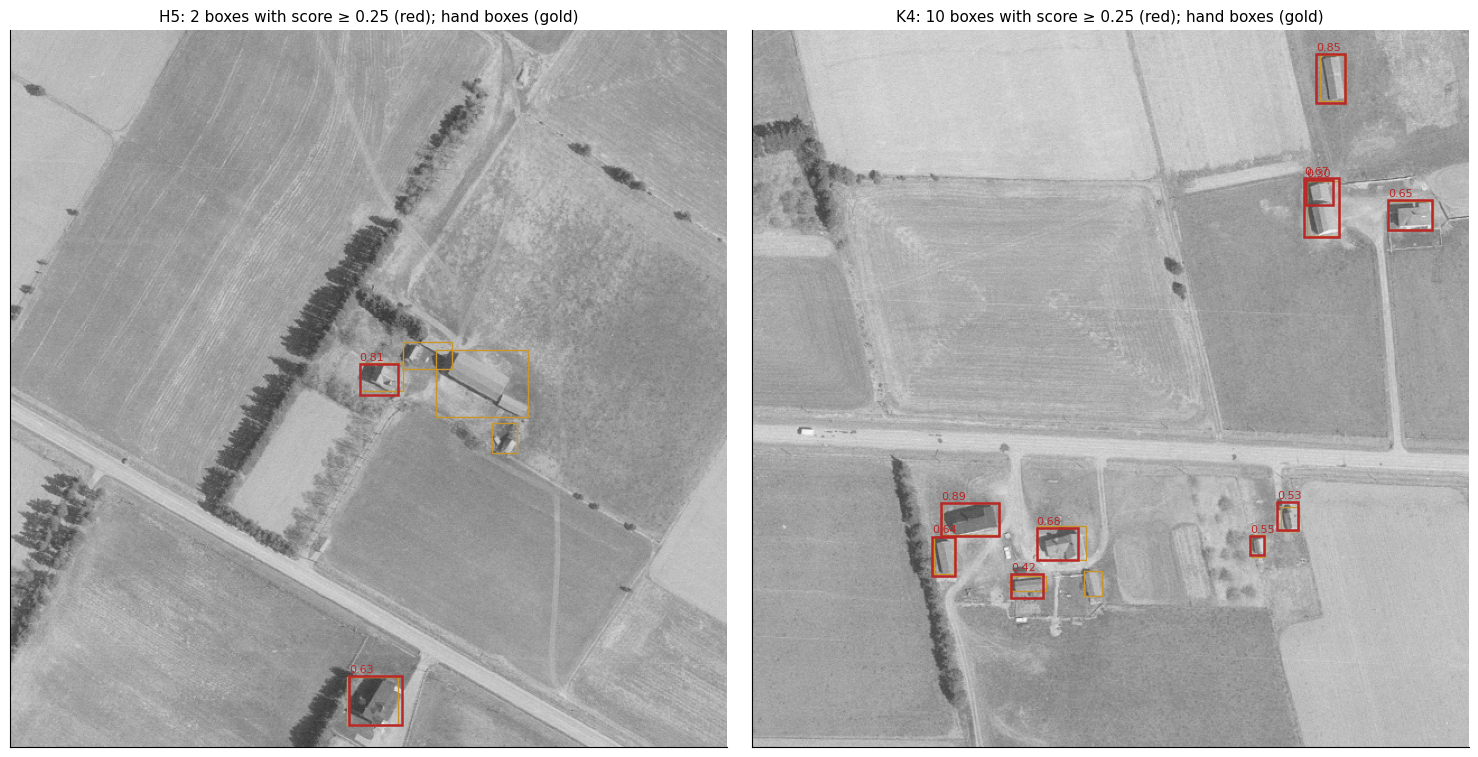

In [24]:
DETS = {t: detect(model, t)[0] for t in TRUTH}       # every box with score >= 0.01, for every tile
DETS_COCO = {t: detect(coco, t)[0] for t in SPLITS["val"]}
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, t in zip(axes, SPLITS["val"]):
    keep = [d for d in DETS[t] if d[4] >= 0.25]
    show(ax, t, f"{t}: {len(keep)} boxes with score ≥ 0.25 (red); hand boxes (gold)")
    draw(ax, TRUTH[t], GOLD, 1.0)
    draw(ax, [d[:4] for d in keep], RED, 1.8, [d[4] for d in keep])
plt.tight_layout(); plt.show()

**Q2.** How close was your prediction? Count by eye: how many of the 15 buildings got a red
box, and how many red boxes are on something else? Why can 14 photos be enough to learn anything?

*Your answer:*

---
## Part 3 — Scoring a detector  `⏱ ~12 min`

Counting by eye does not scale. The rule from L15 §5:

1. Sort the detections by score, **best first**.
2. Each detection takes the **not-yet-taken** true box it overlaps most. If that IoU is **≥ 0.5**
   it is a **true positive (TP)** and the true box is now taken; otherwise it is a **false positive
   (FP)**.
3. True boxes never taken are **misses (FN)**.

**Precision** = TP / (number of detections) · **Recall** = TP / (number of true boxes).

**By hand first.** Two true boxes T1 = (0, 0, 10, 10), T2 = (20, 0, 30, 10) and four detections:

| | box | score |
|---|---|---|
| d1 | (1, 0, 11, 10) | 0.9 |
| d2 | (0, 1, 10, 11) | 0.8 |
| d3 | (20, 0, 30, 10) | 0.7 |
| d4 | (40, 40, 50, 50) | 0.6 |

Which are TP and which FP? What are precision and recall at score ≥ 0.5, and at score ≥ 0.75?

> *Remember that typically a detector does NMS as part of the process with our version of YOLO defaulting to IoU >= 0.7 for suppression but this could be changed to 0.5 or other thresholds. `IoU(d1, d2) = 0.68` for example above.*

**Task 2:** complete `iou` (L15 slide 6) and `match`.

In [29]:
def iou(a, b):
    '''a, b = (x1, y1, x2, y2, ...) -> intersection over union (extra entries such as a score are ignored)'''
    # ── YOUR CODE HERE ──────────────────────────────────────────────────────────

    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))          # overlap width
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))          # overlap height
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

    #──────────────────────────────────────────────────────────────────────────
    raise NotImplementedError("Task 2a: iou")

def match(dets, truth, thr, iou_thr=0.5):
    '''
    dets (detections)  : list of (x1, y1, x2, y2, score), best first
    truth : list of true boxes (x1, y1, x2, y2)
    Keep the detections with score >= thr. Returns
        flags  : one True (TP) / False (FP) per kept detection, in order
        missed : indices of the true boxes that no detection took
    '''
    taken, flags = set(), []
    for d in dets:
        if d[4] < thr:
            continue #skip those that don't pass the threshold
        # ── YOUR CODE HERE ──────────────────────────────────────────────────────
        # find the not-taken true box j with the largest iou(d, truth[j])
        # if that IoU >= iou_thr: flags.append(True) and add j to taken; else flags.append(False)

        #for each detection passing the threshold search through the true boxes
        #and get the highest IoU score. If that passes the threshold mark it TP
        #(and label the truth as taken) otherwise FP.
        #This is a greedy matching, the first TP detection gets the truth.

        cands = [(iou(d, truth[j]), j) for j in range(len(truth)) if j not in taken]

        best, j = max(cands) if cands else (0.0, None)

        #note that flags matches the order of the detections
        if best >= iou_thr:
           flags.append(True); taken.add(j)
        else:
           flags.append(False)
        # ────────────────────────────────────────────────────────────────────────
    return np.array(flags, bool), [j for j in range(len(truth)) if j not in taken]

In [30]:
# Check Task 2 on the by-hand example
try:
    T = [(0, 0, 10, 10), (20, 0, 30, 10)]
    D = [(1, 0, 11, 10, 0.9), (0, 1, 10, 11, 0.8), (20, 0, 30, 10, 0.7), (40, 40, 50, 50, 0.6)]
    print("IoU(d1, T1) =", round(iou(D[0], T[0]), 3), "  IoU(d3, T2) =", round(iou(D[2], T[1]), 3))
    assert abs(iou(D[0], T[0]) - 90 / 110) < 1e-6 and iou(D[3], T[0]) == 0, "check the overlap and the union"
    for thr, want in [(0.5, [True, False, True, False]), (0.75, [True, False])]:
        f, missed = match(D, T, thr)
        print(f"score >= {thr}: flags {f.tolist()}, missed {missed} -> "
              f"P {f.sum()/len(f):.2f}, R {f.sum()/len(T):.2f}")
        assert f.tolist() == want, f"expected {want}: a true box can only be taken once"
    print("Task 2 OK")
except NotImplementedError:
    print("Complete Task 2 first.")

IoU(d1, T1) = 0.818   IoU(d3, T2) = 1.0
score >= 0.5: flags [True, False, True, False], missed [] -> P 0.50, R 1.00
score >= 0.75: flags [True, False], missed [1] -> P 0.50, R 0.50
Task 2 OK


**Q3a.** Check your by-hand answer against the cell. Why is d2 wrong when it overlaps T1 just
as well as d1 does? Which step of a detector (L15 §4) exists to remove boxes like d2?

*Your answer:*

### Precision and recall over several tiles (given)

Add up TP, detections and true boxes over all the tiles of a split, then divide.

In [31]:
def pr_at(dets_by_tile, tiles, thr, iou_thr=0.5):
    n_det = n_tp = n_true = 0
    for t in tiles:
        f, _ = match(dets_by_tile[t], TRUTH[t], thr, iou_thr)
        n_det += len(f); n_tp += int(f.sum()); n_true += len(TRUTH[t])
    return dict(boxes=n_det, TP=n_tp, FP=n_det - n_tp, FN=n_true - n_tp,
                P=round(n_tp / n_det, 2) if n_det else 1.0, R=round(n_tp / n_true, 2))

try:
    print("validation tiles (15 buildings)")
    print("  COCO YOLO, any class, score >= 0.25:", pr_at(DETS_COCO, SPLITS["val"], 0.25))
    for thr in (0.5, 0.25, 0.1):
        print(f"  fine-tuned,         score >= {thr:<4}:", pr_at(DETS, SPLITS["val"], thr))
except NotImplementedError:
    print("Complete Task 2 first.")

validation tiles (15 buildings)
  COCO YOLO, any class, score >= 0.25: {'boxes': 1, 'TP': 0, 'FP': 1, 'FN': 15, 'P': 0.0, 'R': 0.0}
  fine-tuned,         score >= 0.5 : {'boxes': 10, 'TP': 10, 'FP': 0, 'FN': 5, 'P': 1.0, 'R': 0.67}
  fine-tuned,         score >= 0.25: {'boxes': 12, 'TP': 11, 'FP': 1, 'FN': 4, 'P': 0.92, 'R': 0.73}
  fine-tuned,         score >= 0.1 : {'boxes': 18, 'TP': 12, 'FP': 6, 'FN': 3, 'P': 0.67, 'R': 0.8}


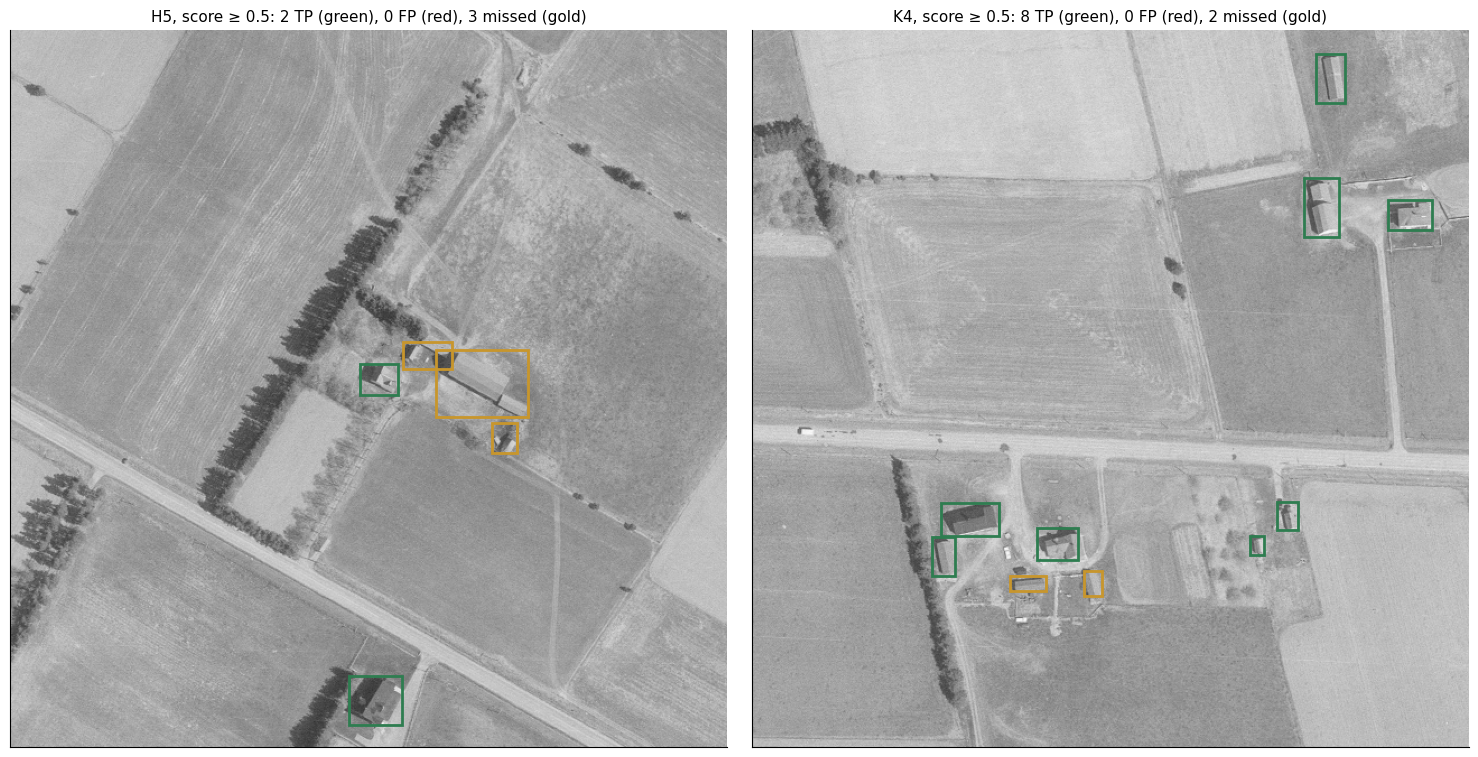

In [33]:
def show_scored(t, thr, ax):
    keep = [d for d in DETS[t] if d[4] >= thr]
    f, missed = match(DETS[t], TRUTH[t], thr)
    show(ax, t, f"{t}, score ≥ {thr}: {f.sum()} TP (green), {len(f) - f.sum()} FP (red), {len(missed)} missed (gold)")
    draw(ax, [d for d, ok in zip(keep, f) if ok], GREEN, 2)
    draw(ax, [d for d, ok in zip(keep, f) if not ok], RED, 2, [d[4] for d, ok in zip(keep, f) if not ok])
    draw(ax, TRUTH[t][missed], GOLD, 2)

try:
    fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
    for ax, t in zip(axes, SPLITS["val"]):
        show_scored(t, 0.5, ax)
    plt.tight_layout(); plt.show()
except NotImplementedError:
    print("Complete Task 2 first.")

**Q3b.** Fill in: at score ≥ 0.25, P = 0.9, R = 0.9; at score ≥ 0.5, P = 1, R = 0.8. Which way did
each one move, and why? Look at the red boxes: what does the network mistake for a building? Look at
the gold ones: what does it miss?

*Your answer:*

---
## Part 4 — The precision–recall curve and AP  `⏱ ~10 min`

A threshold gives **one** (recall, precision) point. Sliding it from high to low adds one detection
at a time: each TP moves the curve **right** (recall up), each FP moves it **down** (precision down).
That is the **precision–recall curve**, and the area under it is **AP** (average precision): 1.0 for a
detector that ranks every building above every non-building, lower otherwise. It does not depend on
any threshold, which is why papers report it.

`pooled` (given) runs `match` with no threshold on every tile and pools the results, so you get one
long list of TP/FP flags with their scores.

`pr_curve`: sorts by score (best first), then a running count of TPs gives
recall and precision after each detection.

`threshold_for_recall`: the **highest**
score threshold whose recall reaches a target.

In [34]:
def pooled(dets_by_tile, tiles, iou_thr=0.5):
    flags, scores, n_true = [], [], 0
    for t in tiles:
        f, _ = match(dets_by_tile[t], TRUTH[t], -1, iou_thr)     # thr -1: keep every detection
        flags += f.tolist(); scores += [d[4] for d in dets_by_tile[t]]; n_true += len(TRUTH[t])
    return np.array(flags, bool), np.array(scores), n_true

def average_precision(rec, prec):
    '''Area under the PR curve, with precision made non-increasing first (as VOC and COCO do).'''
    p = np.maximum.accumulate(prec[::-1])[::-1]
    r = np.concatenate([[0], rec])
    return float(np.sum((r[1:] - r[:-1]) * p))

In [35]:
def pr_curve(flags, scores, n_true):
    '''flags, scores: one entry per detection (any order). Returns rec, prec, s sorted best first.'''
    order = np.argsort(-scores)
    f, s = flags[order], scores[order]
    tp = np.cumsum(f)
    return tp / n_true, tp / np.arange(1, len(f) + 1), s

def threshold_for_recall(rec, prec, s, target):
    '''The highest score threshold whose recall is >= target, and the precision there.'''
    ok = rec >= target
    if not ok.any():
        return None, None
    k = int(np.argmax(ok))# index of the largest value
    return s[k], prec[k]

In [36]:
# Check Task 3 on the by-hand example: d1 TP, d2 FP, d3 TP, d4 FP, two true boxes
try:
    rec, prec, s = pr_curve(np.array([False, True, False, True]), np.array([0.8, 0.9, 0.6, 0.7]), 2)
    print("rec ", rec.round(2), "\nprec", prec.round(2), "\nscore", s)
    assert np.allclose(rec, [0.5, 0.5, 1, 1]) and np.allclose(prec, [1, 0.5, 2/3, 0.5]), "sort, cumsum, divide"
    assert threshold_for_recall(rec, prec, s, 1.0) == (0.7, 2/3), "highest threshold reaching recall 1 is d3's 0.7"
    print("AP =", round(average_precision(rec, prec), 3), " (0.5 x 1.0 + 0.5 x 0.667)")
    print("Task 3 OK")
except NotImplementedError:
    print("Complete Task 3 first.")

rec  [        0.5         0.5           1           1] 
prec [          1         0.5        0.67         0.5] 
score [        0.9         0.8         0.7         0.6]
AP = 0.833  (0.5 x 1.0 + 0.5 x 0.667)
Task 3 OK


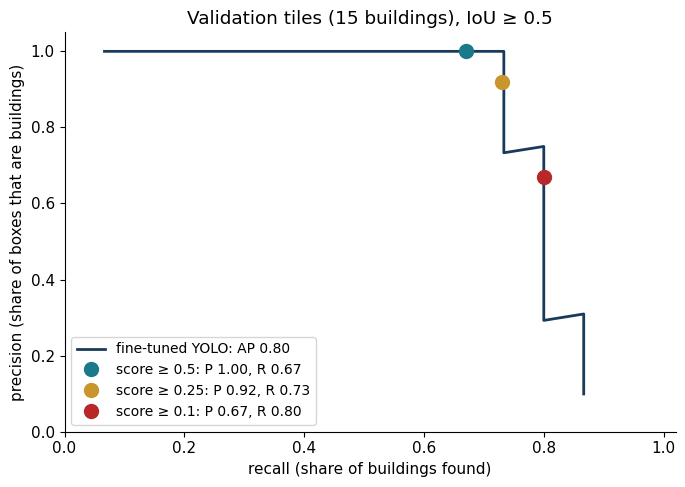

recall >= 0.8: threshold 0.11, precision there 0.75
recall >= 0.9: never reached


In [37]:
try:
    rec, prec, s = pr_curve(*pooled(DETS, SPLITS["val"]))
    AP50 = average_precision(rec, prec)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(rec, prec, color=NAVY, lw=2, label=f"fine-tuned YOLO: AP {AP50:.2f}")
    for thr, col in [(0.5, TEAL), (0.25, GOLD), (0.1, RED)]:
        q = pr_at(DETS, SPLITS["val"], thr)
        ax.plot(q["R"], q["P"], "o", ms=10, color=col, label=f"score ≥ {thr}: P {q['P']:.2f}, R {q['R']:.2f}")
    ax.set_xlabel("recall (share of buildings found)"); ax.set_ylabel("precision (share of boxes that are buildings)")
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05); ax.legend(loc="lower left", fontsize=10)
    ax.set_title("Validation tiles (15 buildings), IoU ≥ 0.5"); plt.tight_layout(); plt.show()
    for target in (0.8, 0.9):
        thr, p = threshold_for_recall(rec, prec, s, target)
        print(f"recall >= {target}: threshold {thr:.2f}, precision there {p:.2f}" if thr is not None
              else f"recall >= {target}: never reached")
except NotImplementedError:
    print("Complete Tasks 2 and 3 first.")

**Q4a.** Two projects use this detector. (i) Count every building in 1968 to compare with
1935, to find farmsteads that disappeared. (ii) Draw a clean map of 1968 buildings for a report.
Which matters more for each, precision or recall? Which threshold would you choose for each, and why?

*Your answer:*

### 🔮 A stricter IoU

COCO also reports AP at IoU ≥ 0.75 ("the box must fit well", not just "the right building").
**Predict first:** will AP on the validation tiles fall a little or a lot? Think about how big our
buildings are in pixels, and how carefully a person can draw a box by eye.

In [38]:
try:
    for it in (0.3, 0.5, 0.75):
        r_, p_, _ = pr_curve(*pooled(DETS, SPLITS["val"], iou_thr=it))
        print(f"IoU >= {it}: AP {average_precision(r_, p_):.2f}")
    AP75 = average_precision(*pr_curve(*pooled(DETS, SPLITS["val"], iou_thr=0.75))[:2])
except NotImplementedError:
    print("Complete Tasks 2 and 3 first.")

IoU >= 0.3: AP 0.84
IoU >= 0.5: AP 0.80
IoU >= 0.75: AP 0.53


**Q4b.** What happened to AP at IoU 0.75, and why? For counting buildings, which IoU would
you use?

*Your answer:*

---
## Part 5 — Crapaud, once  `⏱ ~5 min`

Choose your threshold **now**, from the validation tiles (Q4a, project (i) or (ii)), and write it in
`THR`. Then run the test tiles **once**. Crapaud is 12–20 km from the training farms and was flown on
another day.

Crapaud (33 buildings), score >= 0.08: {'boxes': 40, 'TP': 23, 'FP': 17, 'FN': 10, 'P': 0.57, 'R': 0.7} | AP 0.68


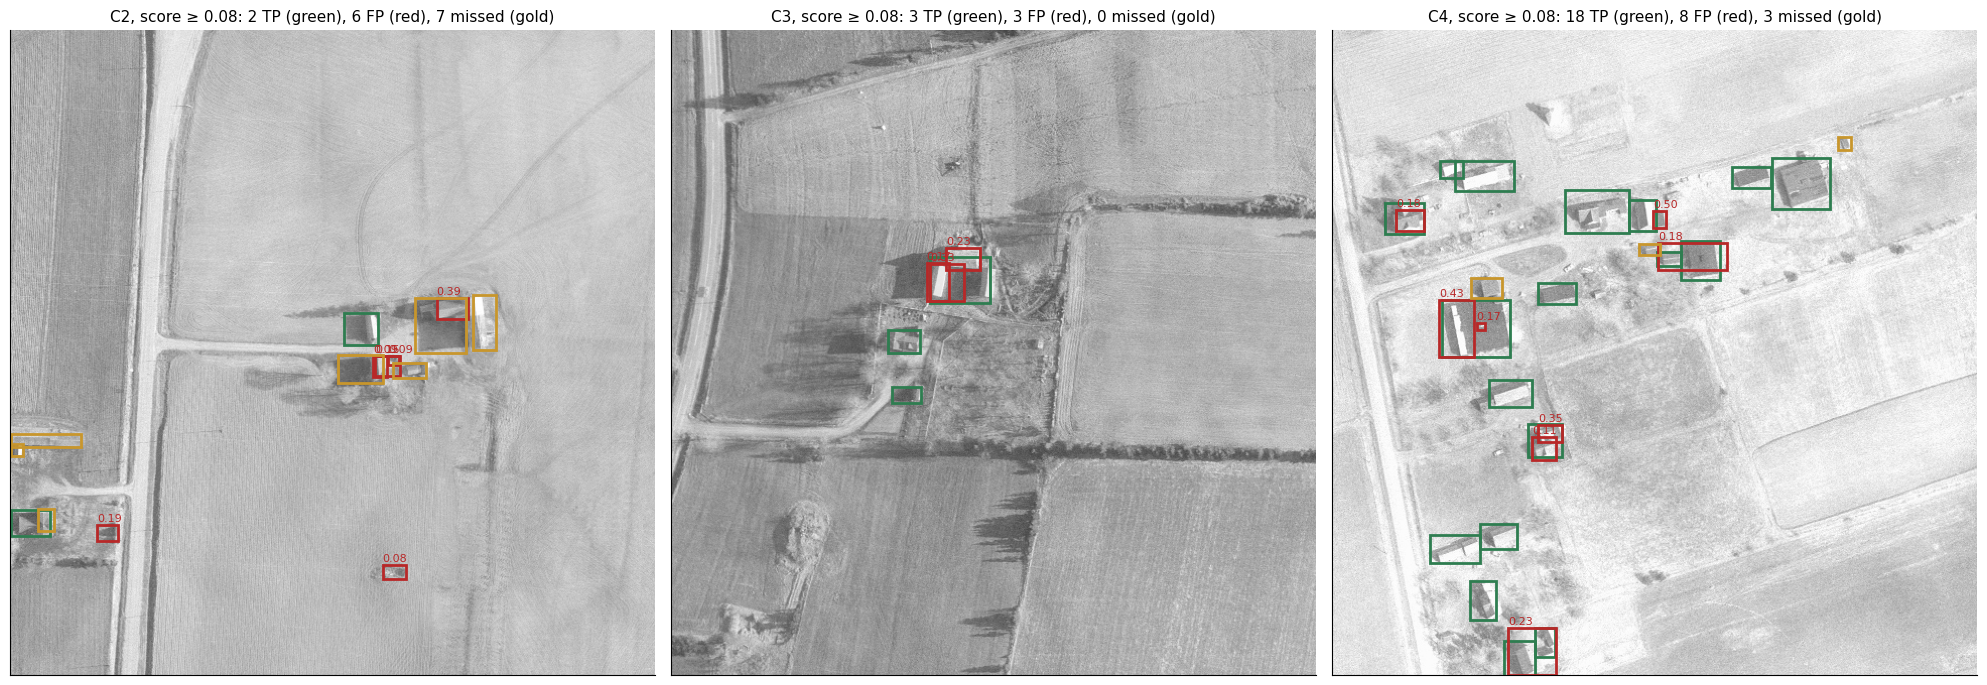

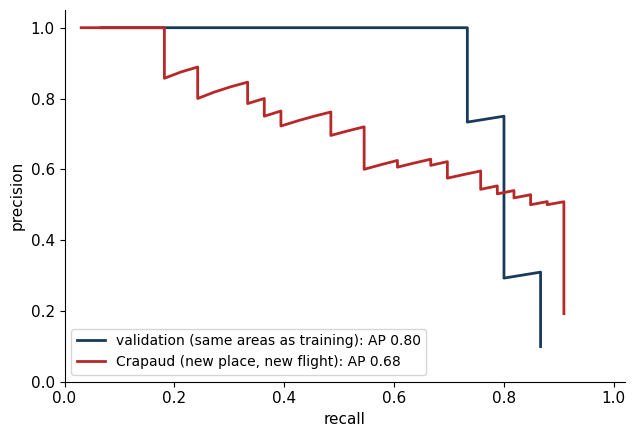

In [39]:
THR = 0.08    # <- your choice from Part 4
try:
    q = pr_at(DETS, SPLITS["test"], THR)
    rt, pt, _ = pr_curve(*pooled(DETS, SPLITS["test"]))
    print(f"Crapaud (33 buildings), score >= {THR}:", q, f"| AP {average_precision(rt, pt):.2f}")
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    for ax, t in zip(axes, SPLITS["test"]):
        show_scored(t, THR, ax)
    plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(rec, prec, color=NAVY, lw=2, label=f"validation (same areas as training): AP {AP50:.2f}")
    ax.plot(rt, pt, color=RED, lw=2, label=f"Crapaud (new place, new flight): AP {average_precision(rt, pt):.2f}")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
    ax.legend(loc="lower left", fontsize=10); plt.tight_layout(); plt.show()
except NotImplementedError:
    print("Complete Tasks 2 and 3 first.")

**Q5.** Report P, R and AP on Crapaud. Better or worse than validation? Compare the photos:
what is different about Crapaud, and what would you do about it in a project?

*Your answer:*

---
## ★ Bonus A — How much does the training data matter?

The first 8 training tiles (H1–H4, K1–K3, K6) were this lab's first version. With only those 8, the
results changed a lot from one training run to the next; adding 6 more tiles made them steadier.
Train again on just those 8 (about 1 minute on a GPU) and compare.

🔮 **Predict first:** with 84 boxes instead of 119, will validation AP go down a little, a lot, or not at all?
Will Crapaud?

In [40]:
SMALL = SPLITS["train"][:8]                      # H1-H4, K1-K3, K6
small_root = os.path.abspath("al9_data_small")
os.makedirs(f"{small_root}/images/train", exist_ok=True); os.makedirs(f"{small_root}/labels/train", exist_ok=True)
try:
    for t in SMALL:
        cv2.imwrite(f"{small_root}/images/train/{t}.png", IMG[t])
        with open(f"{small_root}/labels/train/{t}.txt", "w") as f:
            for b in TRUTH[t]:
                f.write("0 " + " ".join(f"{v:.6f}" for v in to_yolo(b)) + "\n")
    with open(f"{small_root}/data.yaml", "w") as f:
        f.write(f"path: {small_root}\ntrain: images/train\nval: {ROOT}/images/val\nnames:\n  0: building\n")
    small = YOLO("yolo11n.pt")
    small.train(data=f"{small_root}/data.yaml", epochs=EPOCHS, imgsz=640, batch=4, workers=0,
                fliplr=0.5, flipud=0.5, hsv_v=0.6, mosaic=0,
                seed=0, deterministic=True, device=DEVICE, val=False, plots=False, verbose=False,
                project=os.path.abspath("runs_al9"), name="buildings_8", exist_ok=True)
    small = YOLO(os.path.abspath("runs_al9/buildings_8/weights/last.pt"))
    DETS8 = {t: detect(small, t)[0] for t in SPLITS["val"] + SPLITS["test"]}
    print(f"{'':22s}{'val AP':>8s}{'Crapaud AP':>12s}")
    for name, D in [("14 tiles (119 boxes)", DETS), ("8 tiles (84 boxes)", DETS8)]:
        aps = [average_precision(*pr_curve(*pooled(D, SPLITS[s]))[:2]) for s in ("val", "test")]
        print(f"{name:22s}{aps[0]:8.2f}{aps[1]:12.2f}")
except Exception as e:                    # includes NotImplementedError from an unfinished Task 1
    print("Did Parts 1-4 run?", type(e).__name__, e)

                        val AP  Crapaud AP
14 tiles (119 boxes)      0.80        0.68
8 tiles (84 boxes)        0.47        0.39


**QA.** What happened with less data? Compare with your neighbours: whose 8-tile numbers moved the
most from their 14-tile numbers? What does that say about trusting one training run on a small dataset?

*Your answer:*

---
## ★ Bonus B — The same farmstead in 1935

`AL9/K4_1935.png` is validation tile K4 cut from the **1935** orthomosaic, on the same pixel grid.
Run the 1968-trained model on both years.

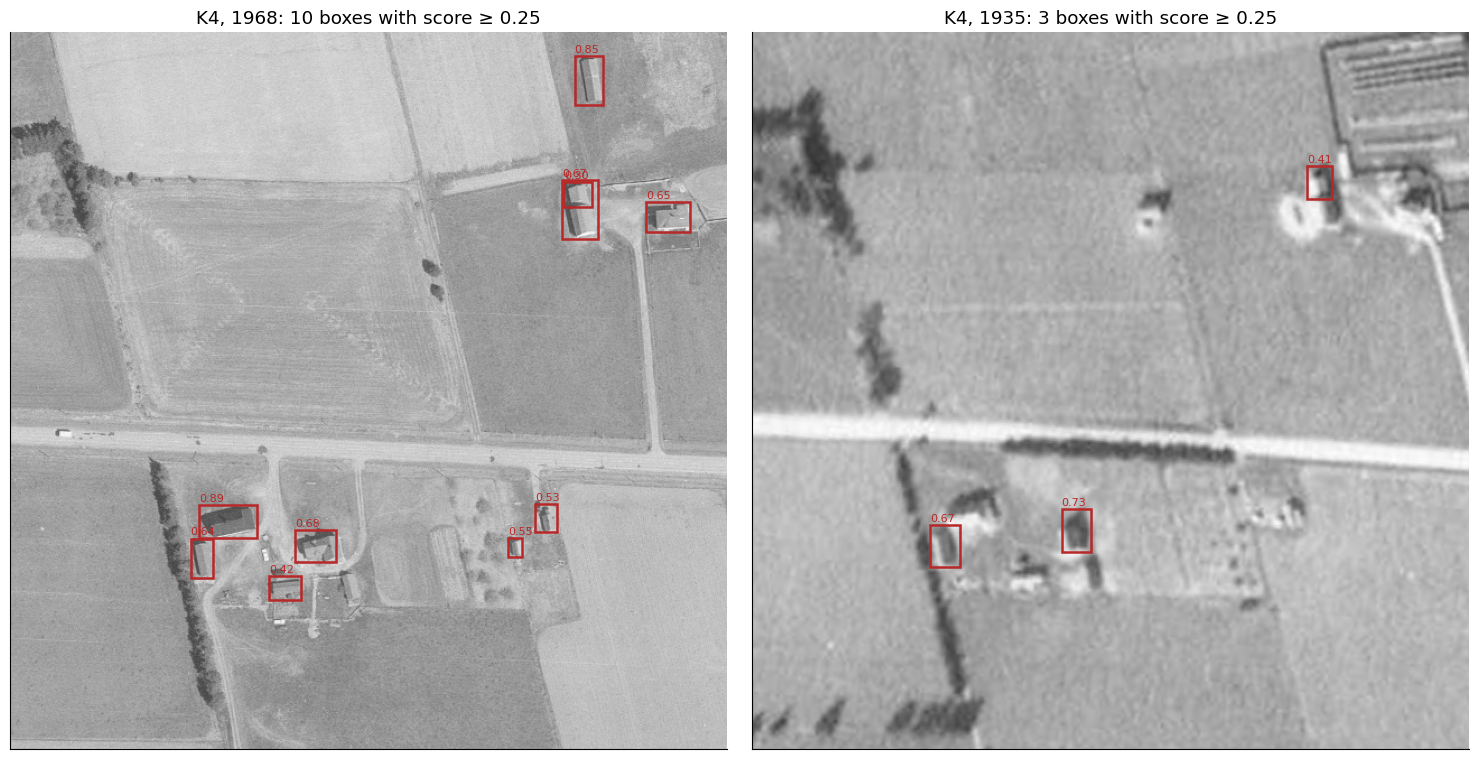

In [41]:
img35 = cv2.imread("AL9/K4_1935.png", cv2.IMREAD_GRAYSCALE)
k68 = [d for d in DETS["K4"] if d[4] >= 0.25]
k35 = [d for d in detect(model, "K4", img=img35)[0] if d[4] >= 0.25]
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, im, k, yr in [(axes[0], IMG["K4"], k68, 1968), (axes[1], img35, k35, 1935)]:
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"K4, {yr}: {len(k)} boxes with score ≥ 0.25"); draw(ax, k, RED, 1.8, [d[4] for d in k])
plt.tight_layout(); plt.show()

**QB.** Can you conclude from the two counts how many buildings were added or removed between
1935 and 1968? What would you need first?

*Your answer:*

---
## Reflection — End of Lab

**R1.** Write the recipe you would use to find buildings in a project's photos, from "label
some tiles" to "report one number". For each step, name the part of today's lab it comes from.

*Your answer:*

**R2.** Every number today rests on 167 boxes drawn by one person. How could the labels
themselves change the precision and recall you report, and how would you check?

*Your answer:*

---
## ✏️ Try at home

Not graded.

**A. Put mosaic back.** Train with `mosaic=1.0` (the default) and compare AP on validation. Look at the
predictions: where do the wrong boxes appear?

**B. Fewer epochs.** Try `EPOCHS = 30` and `60`. When does validation AP stop improving?

**C. Label two tiles of your own.** Cut two 640 × 640 tiles from your project's 1968 image, draw boxes
(any labelling tool, or by reading pixel coordinates off `plt.imshow` with a grid), add them to
`train`, and retrain. Does Crapaud get better? Does your own place?

**D. A looser match.** Re-run Part 4 with `iou_thr=0.3`. When would that be the honest choice?